# AI Job Skill Gap Analyzer

## Part 1 — Project Setup & Dataset

## Project Overview

This project develops an NLP-powered system that compares a user's
technical skills with job descriptions.

The system will:

- Extract technical skills from job descriptions
- Compare user skills with job requirements
- Calculate a job-match score
- Identify matched and missing skills
- Recommend skills to prioritize for learning

## Project Goals

The main goal is to build a practical machine learning system
that can help job seekers understand how well their current
technical skills match a target job.

## Technologies

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Natural Language Processing (NLP)

## Project Workflow

1. Create and explore the job-description dataset
2. Clean and preprocess text
3. Build a technical skill dictionary
4. Extract skills from job descriptions
5. Compare user skills with job requirements
6. Calculate skill-match scores
7. Apply TF-IDF and cosine similarity
8. Identify skill gaps
9. Recommend learning priorities
10. Visualize the results

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

pd.set_option("display.max_colwidth", 120)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
jobs = [
    {
        "job_title": "Junior Data Scientist",
        "category": "Data Science",
        "experience": "Junior",
        "description": (
            "Analyze datasets, build predictive models, and "
            "communicate insights using Python, Pandas, NumPy, "
            "Scikit-learn, SQL, Matplotlib, and statistics."
        ),
        "required_skills": [
            "Python",
            "Pandas",
            "NumPy",
            "Scikit-learn",
            "SQL",
            "Matplotlib",
            "Statistics"
        ]
    },

    {
        "job_title": "Machine Learning Engineer",
        "category": "Machine Learning",
        "experience": "Junior",
        "description": (
            "Develop machine learning pipelines using Python, "
            "Scikit-learn, PyTorch, TensorFlow, Git, Docker, "
            "Linux, SQL, and model evaluation techniques."
        ),
        "required_skills": [
            "Python",
            "Scikit-learn",
            "PyTorch",
            "TensorFlow",
            "Git",
            "Docker",
            "Linux",
            "SQL"
        ]
    },

    {
        "job_title": "Backend Developer",
        "category": "Software Engineering",
        "experience": "Junior",
        "description": (
            "Build backend services and REST APIs using Java, "
            "Spring Boot, SQL, Git, Docker, Linux, and testing."
        ),
        "required_skills": [
            "Java",
            "Spring Boot",
            "SQL",
            "Git",
            "Docker",
            "Linux",
            "REST APIs",
            "Testing"
        ]
    },

    {
        "job_title": "Frontend Developer",
        "category": "Software Engineering",
        "experience": "Junior",
        "description": (
            "Develop responsive web interfaces using HTML, CSS, "
            "JavaScript, React, Git, REST APIs, and testing."
        ),
        "required_skills": [
            "HTML",
            "CSS",
            "JavaScript",
            "React",
            "Git",
            "REST APIs",
            "Testing"
        ]
    },

    {
        "job_title": "Data Analyst",
        "category": "Data Analytics",
        "experience": "Junior",
        "description": (
            "Clean data, write SQL queries, analyze trends, "
            "create visualizations, and report findings using "
            "Python, Pandas, Excel, SQL, Matplotlib, and statistics."
        ),
        "required_skills": [
            "Python",
            "Pandas",
            "Excel",
            "SQL",
            "Matplotlib",
            "Statistics"
        ]
    },

    {
        "job_title": "AI Research Assistant",
        "category": "Artificial Intelligence",
        "experience": "Entry-level",
        "description": (
            "Support experiments in deep learning, neural networks, "
            "Python, NumPy, PyTorch, TensorFlow, mathematics, "
            "statistics, and scientific research."
        ),
        "required_skills": [
            "Python",
            "NumPy",
            "PyTorch",
            "TensorFlow",
            "Mathematics",
            "Statistics",
            "Deep Learning"
        ]
    },

    {
        "job_title": "DevOps Engineer",
        "category": "Cloud and DevOps",
        "experience": "Junior",
        "description": (
            "Automate deployments and manage infrastructure using "
            "Linux, Git, Docker, Kubernetes, AWS, Python, and CI/CD."
        ),
        "required_skills": [
            "Linux",
            "Git",
            "Docker",
            "Kubernetes",
            "AWS",
            "Python",
            "CI/CD"
        ]
    },

    {
        "job_title": "NLP Engineer",
        "category": "Machine Learning",
        "experience": "Junior",
        "description": (
            "Build text-processing systems using Python, NLP, "
            "TF-IDF, Scikit-learn, Transformers, PyTorch, "
            "Pandas, and model evaluation."
        ),
        "required_skills": [
            "Python",
            "NLP",
            "TF-IDF",
            "Scikit-learn",
            "Transformers",
            "PyTorch",
            "Pandas"
        ]
    }
]

df = pd.DataFrame(jobs)

df["required_skills_text"] = df["required_skills"].apply(
    lambda skills: ", ".join(skills)
)

print("Dataset created successfully!")
print("Dataset shape:", df.shape)

Dataset created successfully!
Dataset shape: (8, 6)


In [4]:
df.head()

,job_title,category,experience,description,required_skills,required_skills_text
0,Junior Data Scientist,Data Science,Junior,"Analyze datasets, build predictive models, and communicate insights using Python, Pandas, NumPy, Scikit-learn, SQL, ...","[Python, Pandas, NumPy, Scikit-learn, SQL, Matplotlib, Statistics]","Python, Pandas, NumPy, Scikit-learn, SQL, Matplotlib, Statistics"
1,Machine Learning Engineer,Machine Learning,Junior,"Develop machine learning pipelines using Python, Scikit-learn, PyTorch, TensorFlow, Git, Docker, Linux, SQL, and mod...","[Python, Scikit-learn, PyTorch, TensorFlow, Git, Docker, Linux, SQL]","Python, Scikit-learn, PyTorch, TensorFlow, Git, Docker, Linux, SQL"
2,Backend Developer,Software Engineering,Junior,"Build backend services and REST APIs using Java, Spring Boot, SQL, Git, Docker, Linux, and testing.","[Java, Spring Boot, SQL, Git, Docker, Linux, REST APIs, Testing]","Java, Spring Boot, SQL, Git, Docker, Linux, REST APIs, Testing"
3,Frontend Developer,Software Engineering,Junior,"Develop responsive web interfaces using HTML, CSS, JavaScript, React, Git, REST APIs, and testing.","[HTML, CSS, JavaScript, React, Git, REST APIs, Testing]","HTML, CSS, JavaScript, React, Git, REST APIs, Testing"
4,Data Analyst,Data Analytics,Junior,"Clean data, write SQL queries, analyze trends, create visualizations, and report findings using Python, Pandas, Exce...","[Python, Pandas, Excel, SQL, Matplotlib, Statistics]","Python, Pandas, Excel, SQL, Matplotlib, Statistics"


In [5]:
print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nJob categories:")
print(df["category"].value_counts())

print("\nJob titles:")
print(df["job_title"].tolist())

Dataset shape: (8, 6)

Columns:
['job_title', 'category', 'experience', 'description', 'required_skills', 'required_skills_text']

Job categories:
category
Machine Learning           2
Software Engineering       2
Data Science               1
Data Analytics             1
Artificial Intelligence    1
Cloud and DevOps           1
Name: count, dtype: int64

Job titles:
['Junior Data Scientist', 'Machine Learning Engineer', 'Backend Developer', 'Frontend Developer', 'Data Analyst', 'AI Research Assistant', 'DevOps Engineer', 'NLP Engineer']


In [6]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
job_title               0
category                0
experience              0
description             0
required_skills         0
required_skills_text    0
dtype: int64


## Job Category Distribution

Before building our NLP system, we visualize the distribution
of job categories in our initial dataset.

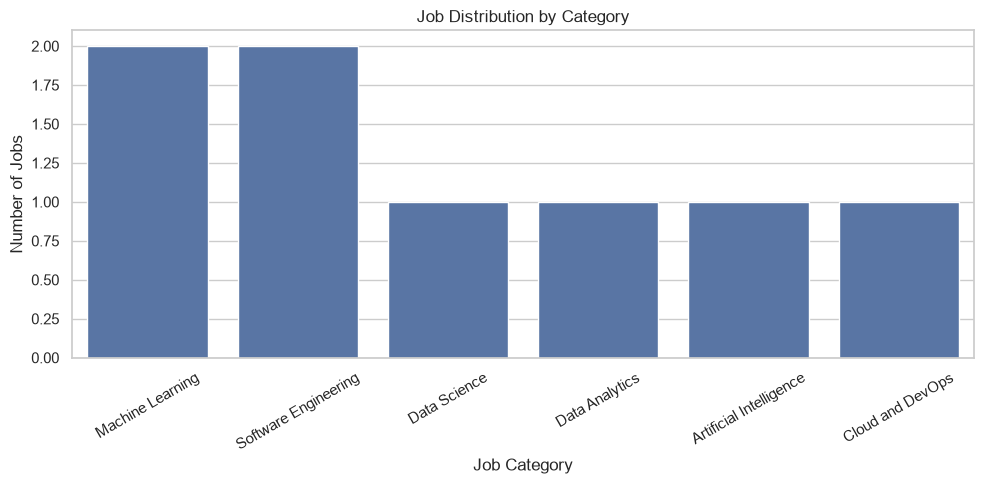

In [7]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="category",
    order=df["category"].value_counts().index
)

plt.title("Job Distribution by Category")
plt.xlabel("Job Category")
plt.ylabel("Number of Jobs")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

## Part 2 — Technical Skill Extraction

## Skill Dictionary

A skill dictionary is a predefined collection of technical skills
that our system knows how to recognize.

This allows us to identify skills inside job descriptions and
compare them with a user's existing skills.

In [8]:
skill_dictionary = [
    "Python",
    "Java",
    "JavaScript",
    "HTML",
    "CSS",
    "React",
    "Spring Boot",
    "SQL",
    "Excel",
    "Pandas",
    "NumPy",
    "Matplotlib",
    "Scikit-learn",
    "PyTorch",
    "TensorFlow",
    "Transformers",
    "NLP",
    "TF-IDF",
    "Machine Learning",
    "Deep Learning",
    "Statistics",
    "Mathematics",
    "Git",
    "Docker",
    "Kubernetes",
    "AWS",
    "Linux",
    "CI/CD",
    "REST APIs",
    "Testing"
]

print("Number of skills:", len(skill_dictionary))
print("\nSkills:")
print(skill_dictionary)

Number of skills: 30

Skills:
['Python', 'Java', 'JavaScript', 'HTML', 'CSS', 'React', 'Spring Boot', 'SQL', 'Excel', 'Pandas', 'NumPy', 'Matplotlib', 'Scikit-learn', 'PyTorch', 'TensorFlow', 'Transformers', 'NLP', 'TF-IDF', 'Machine Learning', 'Deep Learning', 'Statistics', 'Mathematics', 'Git', 'Docker', 'Kubernetes', 'AWS', 'Linux', 'CI/CD', 'REST APIs', 'Testing']


## User Skill Profile

For our first test, we create a sample user profile.

The user already has some programming, data science, and
machine learning experience but is missing several advanced
skills.

In [9]:
user_skills = [
    "Python",
    "Pandas",
    "NumPy",
    "Matplotlib",
    "Scikit-learn",
    "SQL",
    "Git",
    "Java",
    "JavaScript",
    "HTML",
    "CSS"
]

print("User skills:")
for skill in user_skills:
    print("-", skill)

User skills:
- Python
- Pandas
- NumPy
- Matplotlib
- Scikit-learn
- SQL
- Git
- Java
- JavaScript
- HTML
- CSS


## Skill Extraction Function

We now create a function that searches a job description
and identifies which known technical skills appear in it.

The function is case-insensitive so that differences such as
"python", "Python", and "PYTHON" can be recognized as the
same skill.

In [10]:
def extract_skills(text, skill_dictionary):
    text_lower = text.lower()

    found_skills = []

    for skill in skill_dictionary:
        if skill.lower() in text_lower:
            found_skills.append(skill)

    return found_skills

In [11]:
test_description = df.loc[0, "description"]

extracted_skills = extract_skills(
    test_description,
    skill_dictionary
)

print("Job description:")
print(test_description)

print("\nExtracted skills:")
print(extracted_skills)

Job description:
Analyze datasets, build predictive models, and communicate insights using Python, Pandas, NumPy, Scikit-learn, SQL, Matplotlib, and statistics.

Extracted skills:
['Python', 'SQL', 'Pandas', 'NumPy', 'Matplotlib', 'Scikit-learn', 'Statistics']


## Part 3 — Skill Gap Analysis

We compare the user's current skills with the skills required
for a selected job.

The system will identify:

- Matched skills
- Missing skills
- Match percentage

In [12]:
def analyze_skill_gap(user_skills, required_skills):
    user_set = {skill.lower() for skill in user_skills}
    required_set = {skill.lower() for skill in required_skills}

    matched = user_set.intersection(required_set)
    missing = required_set - user_set

    match_percentage = (
        len(matched) / len(required_set) * 100
        if required_set
        else 0
    )

    return matched, missing, match_percentage

In [13]:
job_index = 0

job = df.loc[job_index]

matched, missing, match_percentage = analyze_skill_gap(
    user_skills,
    job["required_skills"]
)

print("Job:", job["job_title"])

print("\nMatched skills:")
for skill in sorted(matched):
    print("✓", skill)

print("\nMissing skills:")
for skill in sorted(missing):
    print("✗", skill)

print(f"\nSkill Match: {match_percentage:.2f}%")

Job: Junior Data Scientist

Matched skills:
✓ matplotlib
✓ numpy
✓ pandas
✓ python
✓ scikit-learn
✓ sql

Missing skills:
✗ statistics

Skill Match: 85.71%


## Test Multiple Jobs

A useful skill-gap analyzer should not only analyze one job.

We will calculate the user's skill match against every job
in our dataset.

In [14]:
results = []

for _, job in df.iterrows():

    matched, missing, match_percentage = analyze_skill_gap(
        user_skills,
        job["required_skills"]
    )

    results.append({
        "job_title": job["job_title"],
        "category": job["category"],
        "match_percentage": match_percentage,
        "matched_skills": list(matched),
        "missing_skills": list(missing)
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    "match_percentage",
    ascending=False
).reset_index(drop=True)

results_df

,job_title,category,match_percentage,matched_skills,missing_skills
0,Junior Data Scientist,Data Science,85.714286,"[python, sql, scikit-learn, matplotlib, pandas, numpy]",[statistics]
1,Data Analyst,Data Analytics,66.666667,"[sql, matplotlib, python, pandas]","[excel, statistics]"
2,Frontend Developer,Software Engineering,57.142857,"[css, git, html, javascript]","[react, testing, rest apis]"
3,Machine Learning Engineer,Machine Learning,50.000000,"[sql, scikit-learn, git, python]","[pytorch, linux, tensorflow, docker]"
4,NLP Engineer,Machine Learning,42.857143,"[scikit-learn, python, pandas]","[pytorch, transformers, tf-idf, nlp]"
5,Backend Developer,Software Engineering,37.500000,"[sql, java, git]","[spring boot, testing, rest apis, linux, docker]"
6,AI Research Assistant,Artificial Intelligence,28.571429,"[numpy, python]","[pytorch, tensorflow, deep learning, mathematics, statistics]"
7,DevOps Engineer,Cloud and DevOps,28.571429,"[git, python]","[aws, kubernetes, linux, docker, ci/cd]"


## Job Compatibility Ranking

We rank jobs according to how closely their required skills
match the user's current skill profile.

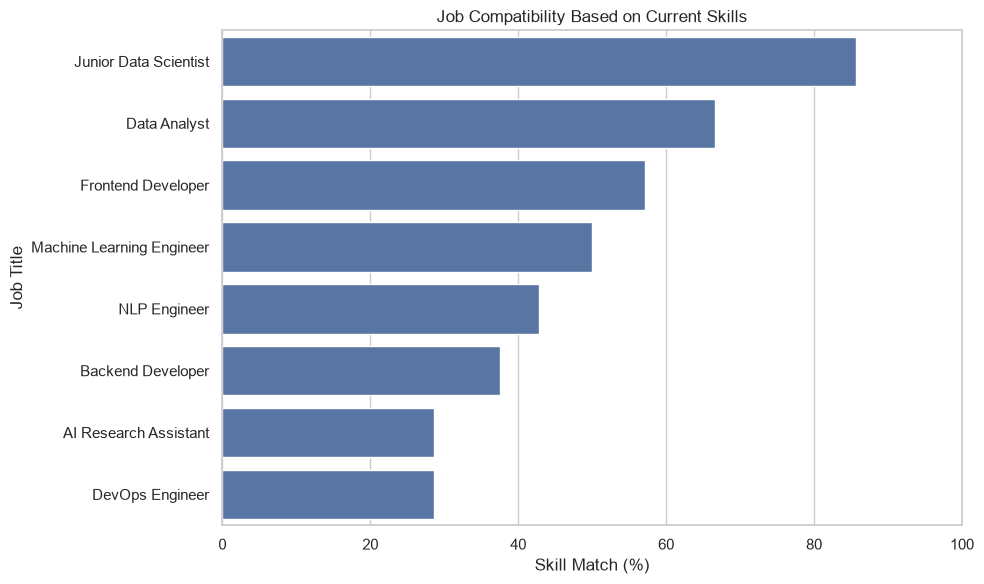

In [15]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="match_percentage",
    y="job_title"
)

plt.title("Job Compatibility Based on Current Skills")
plt.xlabel("Skill Match (%)")
plt.ylabel("Job Title")
plt.xlim(0, 100)

plt.tight_layout()
plt.show()

## Part 4 — Skill Demand & Learning Priority

## Skill Demand Analysis

We now analyze how frequently each technical skill appears
across the job dataset.

This allows us to identify skills that are commonly required
across multiple technology roles.

In [16]:
from collections import Counter

skill_counter = Counter()

for skills in df["required_skills"]:
    for skill in skills:
        skill_counter[skill] += 1

skill_demand = pd.DataFrame(
    skill_counter.items(),
    columns=["skill", "job_count"]
)

skill_demand = skill_demand.sort_values(
    "job_count",
    ascending=False
).reset_index(drop=True)

skill_demand

,skill,job_count
0,Python,6
1,SQL,4
2,Git,4
3,Scikit-learn,3
4,Pandas,3
5,Linux,3
6,Statistics,3
7,Docker,3
8,PyTorch,3
9,NumPy,2


## Most In-Demand Skills

We visualize the technical skills that appear most frequently
across our job dataset.

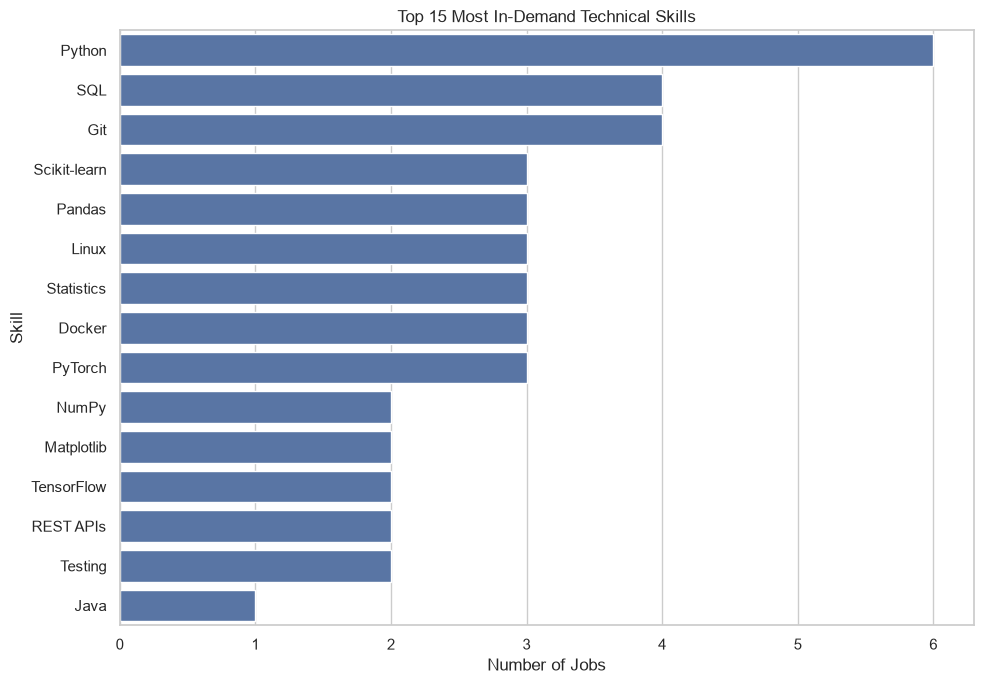

In [17]:
plt.figure(figsize=(10, 7))

top_skills = skill_demand.head(15)

sns.barplot(
    data=top_skills,
    x="job_count",
    y="skill"
)

plt.title("Top 15 Most In-Demand Technical Skills")
plt.xlabel("Number of Jobs")
plt.ylabel("Skill")

plt.tight_layout()

plt.savefig(
    "../images/top_15_skill_demand.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Missing Skill Analysis

A missing skill is more important when it appears frequently
across the available job market.

We therefore combine:

1. Whether the user is missing the skill
2. How many jobs require the skill

This creates a simple learning-priority signal.

In [18]:
user_skill_set = {
    skill.lower()
    for skill in user_skills
}

skill_demand["is_missing"] = skill_demand["skill"].apply(
    lambda skill: skill.lower() not in user_skill_set
)

missing_skill_demand = skill_demand[
    skill_demand["is_missing"]
].copy()

missing_skill_demand

,skill,job_count,is_missing
5,Linux,3,True
6,Statistics,3,True
7,Docker,3,True
8,PyTorch,3,True
11,TensorFlow,2,True
12,REST APIs,2,True
13,Testing,2,True
15,Spring Boot,1,True
19,React,1,True
20,Excel,1,True


## Learning Priority Score

We define a simple priority score based on skill demand.

The more jobs that require a missing skill, the higher its
learning priority.

This is a heuristic ranking rather than a prediction of
employment outcomes.

In [19]:
missing_skill_demand["priority_score"] = (
    missing_skill_demand["job_count"]
    / skill_demand["job_count"].max()
    * 100
)

missing_skill_demand = missing_skill_demand.sort_values(
    "priority_score",
    ascending=False
).reset_index(drop=True)

missing_skill_demand

,skill,job_count,is_missing,priority_score
0,Linux,3,True,50.000000
1,Statistics,3,True,50.000000
2,Docker,3,True,50.000000
3,PyTorch,3,True,50.000000
4,TensorFlow,2,True,33.333333
5,REST APIs,2,True,33.333333
6,Testing,2,True,33.333333
7,Spring Boot,1,True,16.666667
8,React,1,True,16.666667
9,Excel,1,True,16.666667


## Recommended Skills to Learn

The following visualization highlights the most important
missing skills according to their frequency across the
available job descriptions.

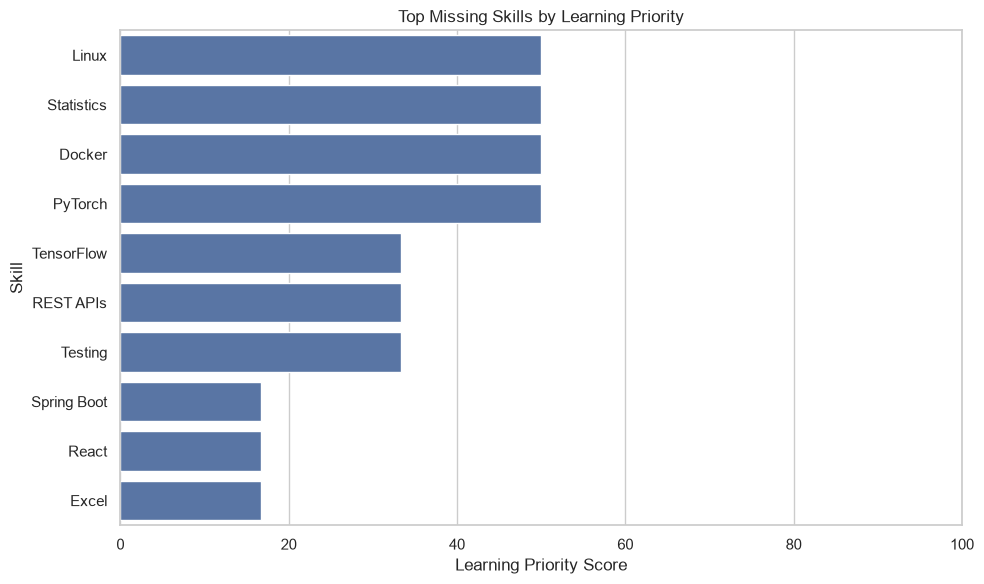

In [20]:
top_missing = missing_skill_demand.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_missing,
    x="priority_score",
    y="skill"
)

plt.title("Top Missing Skills by Learning Priority")
plt.xlabel("Learning Priority Score")
plt.ylabel("Skill")
plt.xlim(0, 100)

plt.tight_layout()

plt.savefig(
    "../images/learning_priority.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Improved Learning Priority

The initial priority score was based only on skill frequency.

We now normalize skill demand against the most frequently
requested skill in the dataset.

Only skills that are currently missing from the user's profile
are considered learning opportunities.

The resulting score is a relative priority indicator, not a
prediction of career success or employment probability.

In [21]:
max_demand = skill_demand["job_count"].max()

missing_skill_demand["demand_score"] = (
    missing_skill_demand["job_count"] / max_demand
)

missing_skill_demand["priority_score"] = (
    missing_skill_demand["demand_score"] * 100
)

missing_skill_demand = missing_skill_demand.sort_values(
    "priority_score",
    ascending=False
).reset_index(drop=True)

missing_skill_demand[
    ["skill", "job_count", "priority_score"]
]

,skill,job_count,priority_score
0,Linux,3,50.000000
1,Statistics,3,50.000000
2,Docker,3,50.000000
3,PyTorch,3,50.000000
4,TensorFlow,2,33.333333
5,REST APIs,2,33.333333
6,Testing,2,33.333333
7,Spring Boot,1,16.666667
8,React,1,16.666667
9,Excel,1,16.666667


## Job-Specific Skill Gaps

A general skill-demand ranking is useful, but a job seeker usually
has a specific target.

We therefore calculate missing skills for each job and connect
them to the user's job-match score.

In [22]:
job_gap_details = []

for _, job in df.iterrows():

    matched, missing, match_percentage = analyze_skill_gap(
        user_skills,
        job["required_skills"]
    )

    job_gap_details.append({
        "job_title": job["job_title"],
        "category": job["category"],
        "match_percentage": match_percentage,
        "matched_count": len(matched),
        "missing_count": len(missing),
        "missing_skills": list(missing)
    })

job_gap_df = pd.DataFrame(job_gap_details)

job_gap_df = job_gap_df.sort_values(
    "match_percentage",
    ascending=False
).reset_index(drop=True)

job_gap_df

,job_title,category,match_percentage,matched_count,missing_count,missing_skills
0,Junior Data Scientist,Data Science,85.714286,6,1,[statistics]
1,Data Analyst,Data Analytics,66.666667,4,2,"[excel, statistics]"
2,Frontend Developer,Software Engineering,57.142857,4,3,"[react, testing, rest apis]"
3,Machine Learning Engineer,Machine Learning,50.000000,4,4,"[pytorch, linux, tensorflow, docker]"
4,NLP Engineer,Machine Learning,42.857143,3,4,"[pytorch, transformers, tf-idf, nlp]"
5,Backend Developer,Software Engineering,37.500000,3,5,"[spring boot, testing, rest apis, linux, docker]"
6,AI Research Assistant,Artificial Intelligence,28.571429,2,5,"[pytorch, tensorflow, deep learning, mathematics, statistics]"
7,DevOps Engineer,Cloud and DevOps,28.571429,2,5,"[aws, kubernetes, linux, docker, ci/cd]"


## Part 5 — Job Recommendation

## Best-Matching Job

We identify the job with the highest skill compatibility
for the current user profile.

In [23]:
best_job = job_gap_df.iloc[0]

print("Recommended Target Role")
print("----------------------")

print("Job:", best_job["job_title"])
print("Category:", best_job["category"])
print(f"Match Score: {best_job['match_percentage']:.2f}%")

print("\nMissing Skills:")

for skill in best_job["missing_skills"]:
    print("-", skill)

Recommended Target Role
----------------------
Job: Junior Data Scientist
Category: Data Science
Match Score: 85.71%

Missing Skills:
- statistics


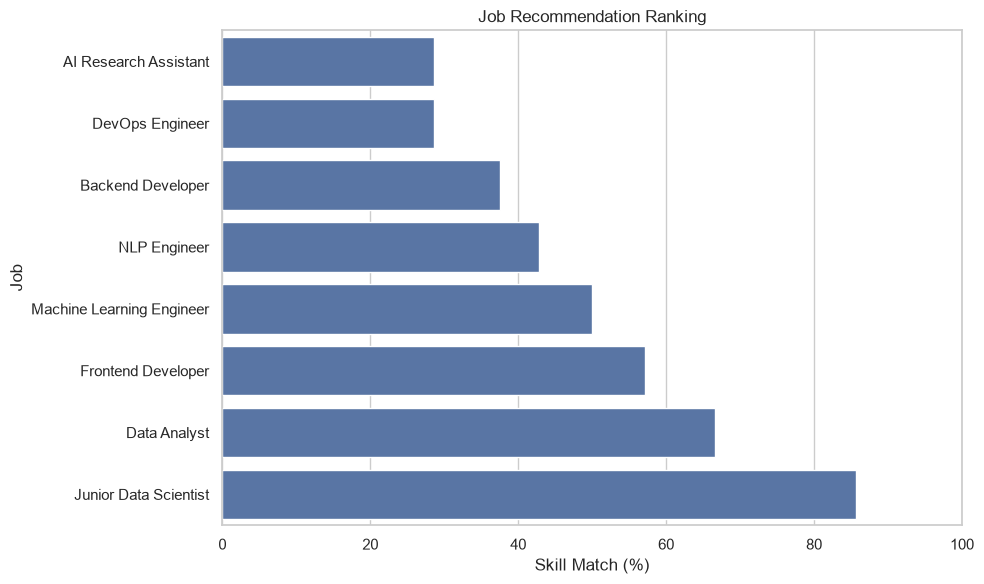

In [24]:
plt.figure(figsize=(10, 6))

plot_df = job_gap_df.sort_values(
    "match_percentage",
    ascending=True
)

sns.barplot(
    data=plot_df,
    x="match_percentage",
    y="job_title"
)

plt.title("Job Recommendation Ranking")
plt.xlabel("Skill Match (%)")
plt.ylabel("Job")

plt.xlim(0, 100)

plt.tight_layout()

plt.savefig(
    "../images/job_recommendation_ranking.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Part 6: NLP-Based Job Similarity

Skill matching tells us whether the user has specific required skills.

However, exact skill matching alone does not capture the overall similarity
between a user's profile and a job description.

In this section, we will use Natural Language Processing (NLP) techniques
to measure the similarity between the user's technical profile and each
job description.

We will use:

- TF-IDF (Term Frequency-Inverse Document Frequency)
- Cosine Similarity

Workflow:

User Profile
↓
TF-IDF Vectorization
↓
Job Description Vectors
↓
Cosine Similarity
↓
NLP Job Similarity Score

In [25]:
user_profile_text = " ".join(user_skills)

print("User Profile:")
print(user_profile_text)

User Profile:
Python Pandas NumPy Matplotlib Scikit-learn SQL Git Java JavaScript HTML CSS


In [26]:
tfidf = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2)
)

all_text = [user_profile_text] + df["description"].tolist()

tfidf_matrix = tfidf.fit_transform(all_text)

print("TF-IDF matrix shape:", tfidf_matrix.shape)

TF-IDF matrix shape: (9, 192)


In [27]:
user_vector = tfidf_matrix[0]
job_vectors = tfidf_matrix[1:]

similarity_scores = cosine_similarity(
    user_vector,
    job_vectors
)[0]

similarity_scores

array([0.27612956, 0.11258237, 0.11214589, 0.17665718, 0.10977012,
       0.03773349, 0.02927952, 0.09737307])

### Comparing the User Profile with Job Descriptions

The cosine similarity score represents how closely the user's technical
profile resembles the content of each job description.

A higher score indicates greater textual similarity.

In [28]:
job_gap_df["tfidf_similarity"] = similarity_scores

job_gap_df[[
    "job_title",
    "match_percentage",
    "tfidf_similarity"
]]

,job_title,match_percentage,tfidf_similarity
0,Junior Data Scientist,85.714286,0.276130
1,Data Analyst,66.666667,0.112582
2,Frontend Developer,57.142857,0.112146
3,Machine Learning Engineer,50.000000,0.176657
4,NLP Engineer,42.857143,0.109770
5,Backend Developer,37.500000,0.037733
6,AI Research Assistant,28.571429,0.029280
7,DevOps Engineer,28.571429,0.097373


### NLP Job Ranking

We will now rank the jobs according to their TF-IDF cosine similarity
with the user's technical profile.

In [29]:
nlp_ranking = job_gap_df.sort_values(
    "tfidf_similarity",
    ascending=False
).reset_index(drop=True)

nlp_ranking[[
    "job_title",
    "tfidf_similarity"
]]

,job_title,tfidf_similarity
0,Junior Data Scientist,0.276130
1,Machine Learning Engineer,0.176657
2,Data Analyst,0.112582
3,Frontend Developer,0.112146
4,NLP Engineer,0.109770
5,DevOps Engineer,0.097373
6,Backend Developer,0.037733
7,AI Research Assistant,0.029280


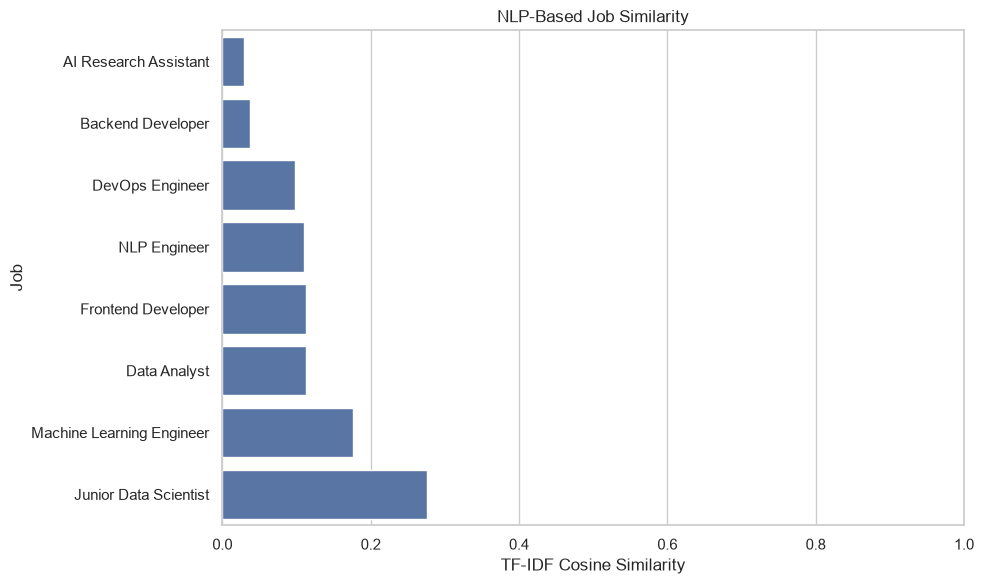

In [30]:
plt.figure(figsize=(10, 6))

plot_df = nlp_ranking.sort_values(
    "tfidf_similarity",
    ascending=True
)

sns.barplot(
    data=plot_df,
    x="tfidf_similarity",
    y="job_title"
)

plt.title("NLP-Based Job Similarity")
plt.xlabel("TF-IDF Cosine Similarity")
plt.ylabel("Job")
plt.xlim(0, 1)

plt.tight_layout()

plt.savefig(
    "../images/tfidf_job_similarity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Part 7: Hybrid Job Compatibility Score

I now combine the two job-matching approaches developed in this project:

1. Explicit Skill Match
2. NLP-Based Text Similarity

The final compatibility score uses:

- 70% Skill Match
- 30% NLP Similarity

This hybrid approach combines interpretable skill coverage with
overall textual similarity between the user's profile and job descriptions.

### Formula

Final Compatibility Score =
    (0.70 × Skill Match) +
    (0.30 × NLP Similarity × 100)

In [31]:
job_gap_df["nlp_similarity_percentage"] = (
    job_gap_df["tfidf_similarity"] * 100
)

job_gap_df["final_score"] = (
    0.70 * job_gap_df["match_percentage"]
    + 0.30 * job_gap_df["nlp_similarity_percentage"]
)

job_gap_df = job_gap_df.sort_values(
    "final_score",
    ascending=False
).reset_index(drop=True)

job_gap_df[[
    "job_title",
    "match_percentage",
    "nlp_similarity_percentage",
    "final_score"
]]

,job_title,match_percentage,nlp_similarity_percentage,final_score
0,Junior Data Scientist,85.714286,27.612956,68.283887
1,Data Analyst,66.666667,11.258237,50.044138
2,Frontend Developer,57.142857,11.214589,43.364377
3,Machine Learning Engineer,50.000000,17.665718,40.299715
4,NLP Engineer,42.857143,10.977012,33.293104
5,Backend Developer,37.500000,3.773349,27.382005
6,DevOps Engineer,28.571429,9.737307,22.921192
7,AI Research Assistant,28.571429,2.927952,20.878386


In [32]:
job_gap_df["match_percentage"] = job_gap_df["match_percentage"].round(2)
job_gap_df["nlp_similarity_percentage"] = job_gap_df["nlp_similarity_percentage"].round(2)
job_gap_df["final_score"] = job_gap_df["final_score"].round(2)

job_gap_df[[
    "job_title",
    "match_percentage",
    "nlp_similarity_percentage",
    "final_score"
]]

,job_title,match_percentage,nlp_similarity_percentage,final_score
0,Junior Data Scientist,85.71,27.61,68.28
1,Data Analyst,66.67,11.26,50.04
2,Frontend Developer,57.14,11.21,43.36
3,Machine Learning Engineer,50.00,17.67,40.30
4,NLP Engineer,42.86,10.98,33.29
5,Backend Developer,37.50,3.77,27.38
6,DevOps Engineer,28.57,9.74,22.92
7,AI Research Assistant,28.57,2.93,20.88


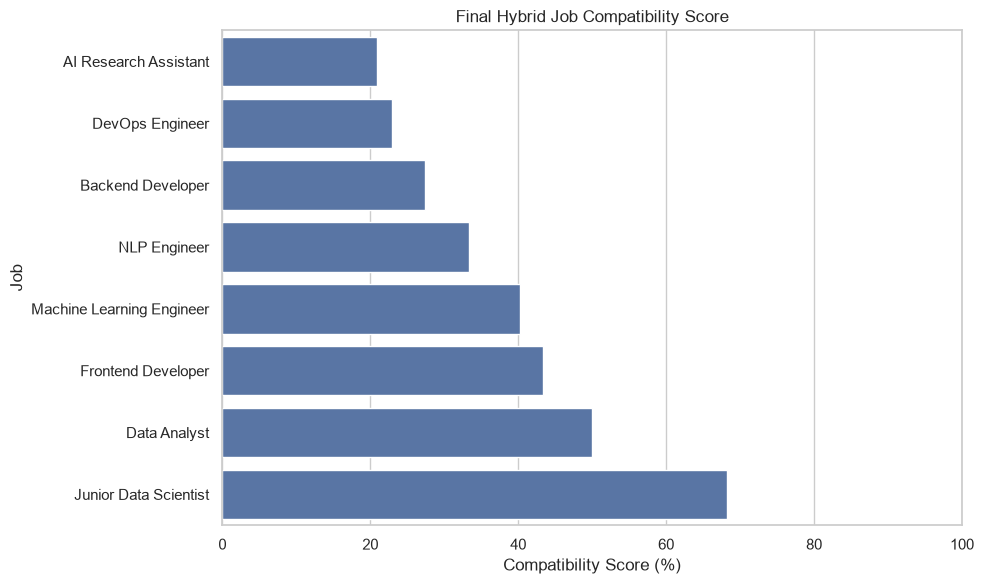

In [33]:
plt.figure(figsize=(10, 6))

plot_df = job_gap_df.sort_values(
    "final_score",
    ascending=True
)

sns.barplot(
    data=plot_df,
    x="final_score",
    y="job_title"
)

plt.title("Final Hybrid Job Compatibility Score")
plt.xlabel("Compatibility Score (%)")
plt.ylabel("Job")
plt.xlim(0, 100)

plt.tight_layout()

plt.savefig(
    "../images/hybrid_job_compatibility.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [34]:
best_job = job_gap_df.iloc[0]

print("🎯 FINAL JOB RECOMMENDATION")
print("=" * 35)

print(f"Job Title: {best_job['job_title']}")
print(f"Category: {best_job['category']}")
print(f"Skill Match: {best_job['match_percentage']:.2f}%")
print(f"NLP Similarity: {best_job['nlp_similarity_percentage']:.2f}%")
print(f"Final Compatibility: {best_job['final_score']:.2f}%")

print("\nMissing Skills:")

for skill in best_job["missing_skills"]:
    print(f"- {skill}")

🎯 FINAL JOB RECOMMENDATION
Job Title: Junior Data Scientist
Category: Data Science
Skill Match: 85.71%
NLP Similarity: 27.61%
Final Compatibility: 68.28%

Missing Skills:
- statistics


# Part 8: Personalized Learning Roadmap

The job matching system has identified the user's missing skills.

In this section, we will turn those skill gaps into a personalized
learning roadmap.

Skills that appear in many job descriptions will receive a higher
priority because learning them can improve compatibility with more
potential jobs.

### Learning Priority Workflow

Missing Skills
↓
Job Demand
↓
Priority Score
↓
Rank Skills
↓
Personalized Learning Roadmap

In [35]:
learning_roadmap = missing_skill_demand[
    ["skill", "job_count", "priority_score"]
].copy()

learning_roadmap["priority_score"] = learning_roadmap[
    "priority_score"
].round(2)

learning_roadmap = learning_roadmap.sort_values(
    "priority_score",
    ascending=False
).reset_index(drop=True)

learning_roadmap

,skill,job_count,priority_score
0,Linux,3,50.00
1,Statistics,3,50.00
2,Docker,3,50.00
3,PyTorch,3,50.00
4,TensorFlow,2,33.33
5,REST APIs,2,33.33
6,Testing,2,33.33
7,Spring Boot,1,16.67
8,React,1,16.67
9,Excel,1,16.67


In [36]:
def assign_priority(score):
    if score >= 40:
        return "High"
    elif score >= 20:
        return "Medium"
    else:
        return "Low"


learning_roadmap["priority_level"] = learning_roadmap[
    "priority_score"
].apply(assign_priority)

learning_roadmap

,skill,job_count,priority_score,priority_level
0,Linux,3,50.00,High
1,Statistics,3,50.00,High
2,Docker,3,50.00,High
3,PyTorch,3,50.00,High
4,TensorFlow,2,33.33,Medium
5,REST APIs,2,33.33,Medium
6,Testing,2,33.33,Medium
7,Spring Boot,1,16.67,Low
8,React,1,16.67,Low
9,Excel,1,16.67,Low


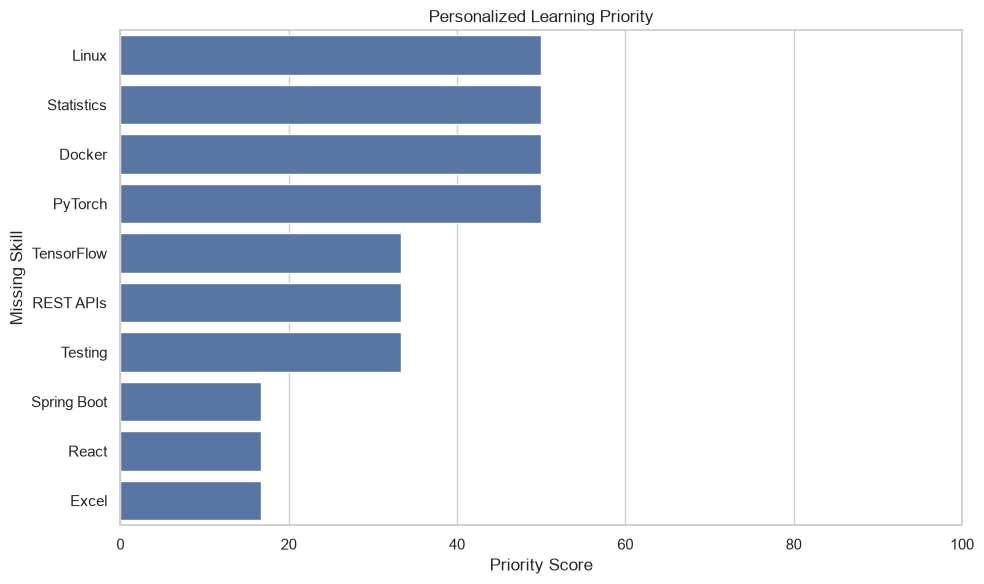

In [37]:
top_learning = learning_roadmap.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_learning,
    x="priority_score",
    y="skill"
)

plt.title("Personalized Learning Priority")
plt.xlabel("Priority Score")
plt.ylabel("Missing Skill")
plt.xlim(0, 100)

plt.tight_layout()

plt.savefig(
    "../images/personalized_learning_roadmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Target-Job Learning Plan

The global learning roadmap considers all available jobs.

We will now create a job-specific learning plan based on the user's
recommended target role.

This helps identify the skills that would have the greatest direct
impact on improving compatibility with the recommended job.

In [38]:
target_job_title = best_job["job_title"]

target_job = df[
    df["job_title"] == target_job_title
].iloc[0]

_, target_missing, target_match = analyze_skill_gap(
    user_skills,
    target_job["required_skills"]
)

print("Target Job:", target_job_title)
print(f"Current Skill Match: {target_match:.2f}%")

print("\nSkills to Learn:")

for skill in target_missing:
    print("-", skill)

Target Job: Junior Data Scientist
Current Skill Match: 85.71%

Skills to Learn:
- statistics


In [39]:
print("🎯 PERSONALIZED CAREER PLAN")
print("=" * 40)

print(f"Target Role: {target_job_title}")
print(f"Current Compatibility: {best_job['final_score']:.2f}%")

print("\nPriority Skills to Learn:")

for skill in target_missing:
    print(f"→ {skill}")

print("\nRecommendation:")
print(
    "Focus on the missing skills above before expanding "
    "into lower-priority technologies."
)

🎯 PERSONALIZED CAREER PLAN
Target Role: Junior Data Scientist
Current Compatibility: 68.28%

Priority Skills to Learn:
→ statistics

Recommendation:
Focus on the missing skills above before expanding into lower-priority technologies.


# Part 9: Final Career Analysis Dashboard

This section combines the results from the complete job skill gap analysis.

The final analysis provides:

- Recommended job
- Compatibility score
- Skill match
- NLP similarity
- Matched skills
- Missing skills
- Learning priorities

This creates a concise career-oriented summary from the complete analysis.

In [40]:
best_job = job_gap_df.iloc[0]

print("╔" + "═" * 58 + "╗")
print("║" + "       AI JOB SKILL GAP ANALYZER - FINAL REPORT       " + "║")
print("╚" + "═" * 58 + "╝")

print("\n🎯 RECOMMENDED JOB")
print("-" * 60)
print(f"Job Title        : {best_job['job_title']}")
print(f"Category         : {best_job['category']}")
print(f"Final Score      : {best_job['final_score']:.2f}%")
print(f"Skill Match      : {best_job['match_percentage']:.2f}%")
print(f"NLP Similarity   : {best_job['nlp_similarity_percentage']:.2f}%")

print("\n✅ MATCHED SKILLS")
print("-" * 60)

matched, missing, _ = analyze_skill_gap(
    user_skills,
    target_job["required_skills"]
)

for skill in sorted(matched):
    print(f"• {skill}")

print("\n❌ MISSING SKILLS")
print("-" * 60)

for skill in sorted(missing):
    print(f"• {skill}")

print("\n📚 TOP LEARNING PRIORITIES")
print("-" * 60)

for _, row in learning_roadmap.head(5).iterrows():
    print(
        f"• {row['skill']} "
        f"({row['priority_level']} priority)"
    )

╔══════════════════════════════════════════════════════════╗
║       AI JOB SKILL GAP ANALYZER - FINAL REPORT       ║
╚══════════════════════════════════════════════════════════╝

🎯 RECOMMENDED JOB
------------------------------------------------------------
Job Title        : Junior Data Scientist
Category         : Data Science
Final Score      : 68.28%
Skill Match      : 85.71%
NLP Similarity   : 27.61%

✅ MATCHED SKILLS
------------------------------------------------------------
• matplotlib
• numpy
• pandas
• python
• scikit-learn
• sql

❌ MISSING SKILLS
------------------------------------------------------------
• statistics

📚 TOP LEARNING PRIORITIES
------------------------------------------------------------
• Linux (High priority)
• Statistics (High priority)
• Docker (High priority)
• PyTorch (High priority)
• TensorFlow (Medium priority)


In [41]:
final_job_ranking = job_gap_df[
    [
        "job_title",
        "category",
        "match_percentage",
        "nlp_similarity_percentage",
        "final_score"
    ]
].head(5).copy()

final_job_ranking

,job_title,category,match_percentage,nlp_similarity_percentage,final_score
0,Junior Data Scientist,Data Science,85.71,27.61,68.28
1,Data Analyst,Data Analytics,66.67,11.26,50.04
2,Frontend Developer,Software Engineering,57.14,11.21,43.36
3,Machine Learning Engineer,Machine Learning,50.00,17.67,40.30
4,NLP Engineer,Machine Learning,42.86,10.98,33.29


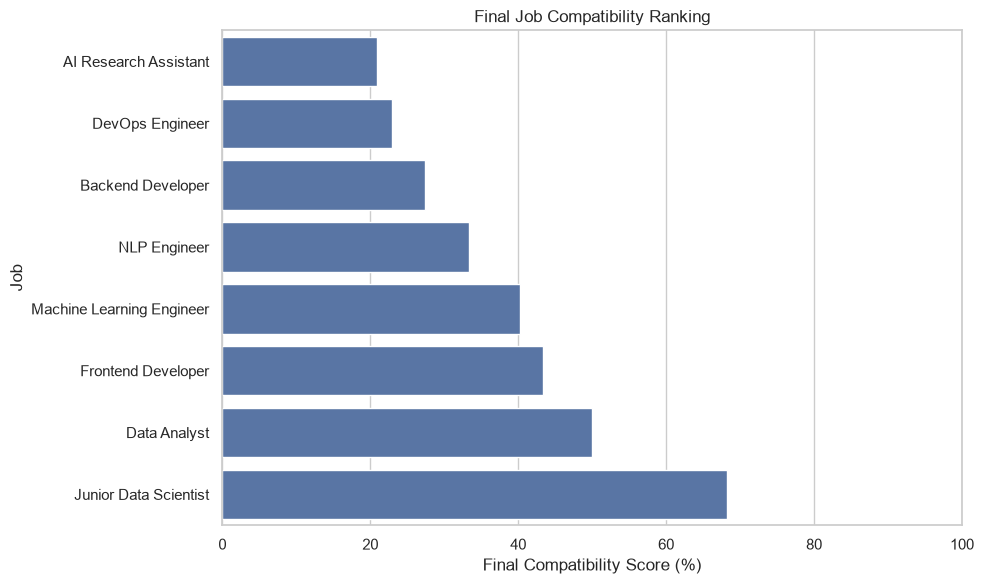

In [42]:
plt.figure(figsize=(10, 6))

plot_df = job_gap_df.sort_values(
    "final_score",
    ascending=True
)

sns.barplot(
    data=plot_df,
    x="final_score",
    y="job_title"
)

plt.title("Final Job Compatibility Ranking")
plt.xlabel("Final Compatibility Score (%)")
plt.ylabel("Job")
plt.xlim(0, 100)

plt.tight_layout()

plt.savefig(
    "../images/final_job_ranking.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Part 10: Export Analysis Results

The final results will be exported as CSV files so that the analysis
outputs can be inspected and reused outside the notebook.

Exported files include:

- Job compatibility rankings
- Learning priorities
- Job descriptions

In [43]:
job_gap_df.to_csv(
    "../data/job_compatibility_results.csv",
    index=False
)

print("Saved: data/job_compatibility_results.csv")

Saved: data/job_compatibility_results.csv


In [44]:
learning_roadmap.to_csv(
    "../data/learning_roadmap.csv",
    index=False
)

print("Saved: data/learning_roadmap.csv")

Saved: data/learning_roadmap.csv


In [45]:
df.to_csv(
    "../data/job_descriptions.csv",
    index=False
)

print("Saved: data/job_descriptions.csv")

Saved: data/job_descriptions.csv


# Part 11: Robust Skill Extraction

The initial skill extraction method used simple substring matching.

Although this works for many skills, substring matching can produce
false positives when one skill name appears inside another skill name.

For example:

- "Java" appears inside "JavaScript"

We will improve the extraction method using boundary-aware matching.

This makes the skill extraction process more reliable and suitable
for a portfolio-quality NLP application.

In [46]:
import re

In [47]:
def extract_skills(text, skill_dictionary):
    text_lower = text.lower()
    found_skills = []

    for skill in skill_dictionary:
        pattern = r"(?<!\w)" + re.escape(skill.lower()) + r"(?!\w)"

        if re.search(pattern, text_lower):
            found_skills.append(skill)

    return found_skills

In [48]:
test_text = """
This position requires JavaScript, HTML, CSS, React, SQL,
and experience with REST APIs.
"""

test_skills = extract_skills(
    test_text,
    skill_dictionary
)

print("Extracted skills:")
print(test_skills)

Extracted skills:
['JavaScript', 'HTML', 'CSS', 'React', 'SQL', 'REST APIs']


# Part 12: Final Project Validation

This section performs a final validation of the job skill gap analyzer.

We will verify:

- Dataset integrity
- User skill profile
- Job compatibility results
- Learning roadmap
- Exported files
- Final recommendation

In [49]:
print("PROJECT VALIDATION")
print("=" * 50)

print(f"Number of jobs: {len(df)}")
print(f"Number of skills in dictionary: {len(skill_dictionary)}")
print(f"Number of user skills: {len(user_skills)}")
print(f"Number of ranked jobs: {len(job_gap_df)}")
print(f"Number of learning recommendations: {len(learning_roadmap)}")

PROJECT VALIDATION
Number of jobs: 8
Number of skills in dictionary: 30
Number of user skills: 11
Number of ranked jobs: 8
Number of learning recommendations: 18


In [50]:
best_job = job_gap_df.iloc[0]

print("\nFINAL RECOMMENDATION")
print("=" * 50)

print(f"Job: {best_job['job_title']}")
print(f"Category: {best_job['category']}")
print(f"Skill Match: {best_job['match_percentage']:.2f}%")
print(f"NLP Similarity: {best_job['nlp_similarity_percentage']:.2f}%")
print(f"Final Score: {best_job['final_score']:.2f}%")


FINAL RECOMMENDATION
Job: Junior Data Scientist
Category: Data Science
Skill Match: 85.71%
NLP Similarity: 27.61%
Final Score: 68.28%


In [51]:
import os

required_files = [
    "../data/job_descriptions.csv",
    "../data/job_compatibility_results.csv",
    "../data/learning_roadmap.csv",
    "../images/top_15_skill_demand.png",
    "../images/learning_priority.png",
    "../images/job_recommendation_ranking.png",
    "../images/tfidf_job_similarity.png",
    "../images/hybrid_job_compatibility.png",
    "../images/personalized_learning_roadmap.png",
    "../images/final_job_ranking.png"
]

print("FILE VALIDATION")
print("=" * 50)

for file in required_files:
    status = "✓ FOUND" if os.path.exists(file) else "✗ MISSING"
    print(f"{status}: {file}")

FILE VALIDATION
✓ FOUND: ../data/job_descriptions.csv
✓ FOUND: ../data/job_compatibility_results.csv
✓ FOUND: ../data/learning_roadmap.csv
✓ FOUND: ../images/top_15_skill_demand.png
✓ FOUND: ../images/learning_priority.png
✓ FOUND: ../images/job_recommendation_ranking.png
✓ FOUND: ../images/tfidf_job_similarity.png
✓ FOUND: ../images/hybrid_job_compatibility.png
✓ FOUND: ../images/personalized_learning_roadmap.png
✓ FOUND: ../images/final_job_ranking.png


In [53]:
print("\n" + "=" * 60)
print("AI JOB SKILL GAP ANALYZER")
print("=" * 60)

top_missing_skill = (
    sorted(target_missing)[0]
    if target_missing
    else "None"
)

print(f"""
Recommended Role:
    {best_job['job_title']}

Category:
    {best_job['category']}

Final Compatibility:
    {best_job['final_score']:.2f}%

Skill Match:
    {best_job['match_percentage']:.2f}%

NLP Similarity:
    {best_job['nlp_similarity_percentage']:.2f}%

Top Missing Skill for Target Role:
    {top_missing_skill}

Total Jobs Analyzed:
    {len(df)}
""")

print("Project validation completed successfully! 🚀")


AI JOB SKILL GAP ANALYZER

Recommended Role:
    Junior Data Scientist

Category:
    Data Science

Final Compatibility:
    68.28%

Skill Match:
    85.71%

NLP Similarity:
    27.61%

Top Missing Skill for Target Role:
    statistics

Total Jobs Analyzed:
    8

Project validation completed successfully! 🚀


In [54]:
import sys
sys.path.append("../src")

from skill_analyzer import extract_skills, analyze_skill_gap

print("Source module imported successfully!")

test_text = "Python, JavaScript, SQL, and REST APIs are required."

print(
    "Extracted:",
    extract_skills(test_text, skill_dictionary)
)

Source module imported successfully!
Extracted: ['Python', 'JavaScript', 'SQL', 'REST APIs']


## Part 13 — Robust Skill Extraction

### Testing the Reusable Source Module

The core skill extraction and skill-gap analysis functions are stored in `src/skill_analyzer.py`.

This test confirms that the notebook can successfully import and use the reusable functions from the project source module.